# Smart Banking Analytics — Semaine 2
## Analyse exploratoire des données (EDA) et contrôle qualité

**Objectif :** comprendre le dataset, vérifier sa qualité, analyser les variables financières et la variable cible `TARGET`, puis documenter les décisions de préparation.

> Important : ce notebook est un modèle exécutable et adaptable. Les noms de fichiers et colonnes sont détectés autant que possible, mais doivent être vérifiés avec le dictionnaire réel du dataset. Aucun résultat chiffré n'est prérempli : ils seront calculés à partir de vos fichiers.


## 0. Préparation de l'environnement
Placez vos fichiers CSV dans `data/raw/`. Le notebook peut analyser un fichier principal ou plusieurs tables liées.

In [12]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Le notebook peut être lancé depuis la racine ou depuis le dossier notebooks.
# On cherche le premier dossier parent qui contient réellement data/raw.
PROJECT_DIR = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents]
     if (parent / "data" / "raw").is_dir()),
    Path.cwd(),
)
RAW_DIR = PROJECT_DIR / "data" / "raw"
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier courant :", PROJECT_DIR)
print("Dossier données :", RAW_DIR)
print("CSV trouvés :", [p.name for p in RAW_DIR.glob("*.csv")])


Dossier courant : c:\Users\manal\OneDrive\Desktop\Smart-Banking-Analytics
Dossier données : c:\Users\manal\OneDrive\Desktop\Smart-Banking-Analytics\data\raw
CSV trouvés : ['assets.csv', 'bureau_monthly.csv', 'clients.csv', 'credit_applications.csv', 'credit_history.csv', 'decision_scenarios.csv', 'financial_profiles.csv', 'insurance.csv', 'repayments.csv']


## 1. Chargement des fichiers

In [13]:
csv_files = sorted(RAW_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        "Aucun CSV trouvé. Créez data/raw/ et placez-y les fichiers du dataset."
    )

dataframes = {}
for path in csv_files:
    try:
        df = pd.read_csv(path, low_memory=False)
        dataframes[path.stem] = df
        print(f"{path.name}: {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
    except Exception as exc:
        print(f"Erreur de lecture de {path.name}: {exc}")

print("\nTables chargées :", list(dataframes))


assets.csv: 50,000 lignes × 10 colonnes
bureau_monthly.csv: 300,000 lignes × 8 colonnes
clients.csv: 50,000 lignes × 19 colonnes
credit_applications.csv: 50,000 lignes × 12 colonnes
credit_history.csv: 82,500 lignes × 9 colonnes
decision_scenarios.csv: 50,000 lignes × 12 colonnes
financial_profiles.csv: 50,000 lignes × 15 colonnes
insurance.csv: 50,000 lignes × 7 colonnes
repayments.csv: 600,000 lignes × 10 colonnes

Tables chargées : ['assets', 'bureau_monthly', 'clients', 'credit_applications', 'credit_history', 'decision_scenarios', 'financial_profiles', 'insurance', 'repayments']


## 2. Choisir la table principale
Sélectionnez la table contenant une ligne par demande de crédit et la variable `TARGET`. Si vos noms diffèrent, modifiez `MAIN_TABLE`.

In [14]:
# Exemple : "credit_applications". Remplacez par le nom réel sans extension .csv.
MAIN_TABLE = next(
    (name for name, df in dataframes.items() if "TARGET" in df.columns),
    list(dataframes.keys())[0]
)
df = dataframes[MAIN_TABLE].copy()

print("Table principale :", MAIN_TABLE)
display(df.head())
print("Dimensions :", df.shape)


Table principale : credit_applications


,SK_ID_CURR,APPLICATION_DATE,CREDIT_TYPE,AMOUNT_REQUESTED_MAD,CREDIT_TERM_MONTHS,INTEREST_RATE_ANNUAL_PCT,ESTIMATED_MONTHLY_INSTALLMENT_MAD,CREDIT_TO_ANNUAL_INCOME,PAYMENT_TO_INCOME_RATIO,DEBT_TO_INCOME_RATIO,TARGET,TARGET_LABEL
0,100000,2025-10-19,Automobile,28390,72,11.040,540.960,0.544,0.201,0.572,0,Remboursement sans défaut observé
1,100001,2023-02-12,Automobile,5000,60,7.970,101.310,0.783,0.322,0.804,1,Défaut observé
2,100002,2024-04-12,Personnel,69103,60,9.860,"1,463.480",0.412,0.130,0.415,0,Remboursement sans défaut observé
3,100003,2024-05-06,Équipement,16695,36,9.570,535.340,0.481,0.352,0.541,0,Remboursement sans défaut observé
4,100004,2024-10-04,Automobile,34424,60,7.960,697.340,0.448,0.297,0.532,0,Remboursement sans défaut observé


Dimensions : (50000, 12)


## 3. Structure et types des variables

In [15]:
structure = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs_non_nulles": df.notna().sum(),
    "valeurs_manquantes": df.isna().sum(),
    "taux_manquant_%": (df.isna().mean() * 100).round(2),
    "valeurs_uniques": df.nunique(dropna=True)
}).sort_values("taux_manquant_%", ascending=False)

display(structure)
structure.to_csv(REPORT_DIR / "structure_variables.csv", index=True)


,type,valeurs_non_nulles,valeurs_manquantes,taux_manquant_%,valeurs_uniques
SK_ID_CURR,int64,50000,0,0.000,50000
APPLICATION_DATE,str,50000,0,0.000,1095
CREDIT_TYPE,str,50000,0,0.000,5
AMOUNT_REQUESTED_MAD,int64,50000,0,0.000,40244
CREDIT_TERM_MONTHS,int64,50000,0,0.000,13
INTEREST_RATE_ANNUAL_PCT,float64,50000,0,0.000,1272
ESTIMATED_MONTHLY_INSTALLMENT_MAD,float64,50000,0,0.000,46863
CREDIT_TO_ANNUAL_INCOME,float64,50000,0,0.000,17256
PAYMENT_TO_INCOME_RATIO,float64,50000,0,0.000,9179
DEBT_TO_INCOME_RATIO,float64,50000,0,0.000,18456


## 4. Qualité des données : valeurs manquantes, doublons et constantes

In [16]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct.round(2)
})
display(missing_report[missing_report["missing_count"] > 0])

duplicate_rows = int(df.duplicated().sum())
print(f"Nombre de lignes dupliquées : {duplicate_rows:,}")
print("Colonnes constantes :", [c for c in df.columns if df[c].nunique(dropna=False) <= 1])

if missing_report["missing_count"].sum() > 0:
    ax = missing_report.query("missing_count > 0").head(25)["missing_percent"].sort_values().plot(
        kind="barh", figsize=(9, 6), title="Taux de valeurs manquantes — 25 premières colonnes"
    )
    ax.set_xlabel("Valeurs manquantes (%)")
    plt.tight_layout()
    plt.show()


,missing_count,missing_percent


Nombre de lignes dupliquées : 0
Colonnes constantes : []


## 5. Vérification des identifiants et des relations entre tables

In [17]:
# Vérification indicative des clés usuelles. Adaptez selon le dictionnaire de données.
candidate_keys = ["SK_ID_CURR", "client_id", "application_id", "SK_ID_PREV"]

for table_name, table in dataframes.items():
    print(f"\n--- {table_name} ---")
    for key in candidate_keys:
        if key in table.columns:
            print(
                key,
                "| uniques:", table[key].nunique(dropna=True),
                "| nulls:", int(table[key].isna().sum()),
                "| doublons:", int(table[key].duplicated().sum())
            )

# Vérifier les clés communes entre tables
for i, (name_a, a) in enumerate(dataframes.items()):
    for name_b, b in list(dataframes.items())[i+1:]:
        common = sorted(set(a.columns).intersection(b.columns))
        likely = [c for c in common if c.lower() in {
            "sk_id_curr", "client_id", "application_id", "sk_id_prev"
        }]
        if likely:
            print(f"{name_a} ↔ {name_b}: clés candidates {likely}")



--- assets ---
SK_ID_CURR | uniques: 50000 | nulls: 0 | doublons: 0

--- bureau_monthly ---
SK_ID_CURR | uniques: 49867 | nulls: 0 | doublons: 250133

--- clients ---
SK_ID_CURR | uniques: 50000 | nulls: 0 | doublons: 0

--- credit_applications ---
SK_ID_CURR | uniques: 50000 | nulls: 0 | doublons: 0

--- credit_history ---
SK_ID_CURR | uniques: 40393 | nulls: 0 | doublons: 42107

--- decision_scenarios ---
SK_ID_CURR | uniques: 50000 | nulls: 0 | doublons: 0

--- financial_profiles ---
SK_ID_CURR | uniques: 50000 | nulls: 0 | doublons: 0

--- insurance ---
SK_ID_CURR | uniques: 50000 | nulls: 0 | doublons: 0

--- repayments ---
SK_ID_CURR | uniques: 50000 | nulls: 0 | doublons: 550000
assets ↔ bureau_monthly: clés candidates ['SK_ID_CURR']
assets ↔ clients: clés candidates ['SK_ID_CURR']
assets ↔ credit_applications: clés candidates ['SK_ID_CURR']
assets ↔ credit_history: clés candidates ['SK_ID_CURR']
assets ↔ decision_scenarios: clés candidates ['SK_ID_CURR']
assets ↔ financial_pro

## 6. Analyse de la variable cible TARGET
`TARGET` doit représenter un événement de défaut défini à l'avance. Il ne doit pas être confondu avec la décision d'octroi du crédit.

,effectif,pourcentage
TARGET,,
0,40562,81.120
1,9438,18.880


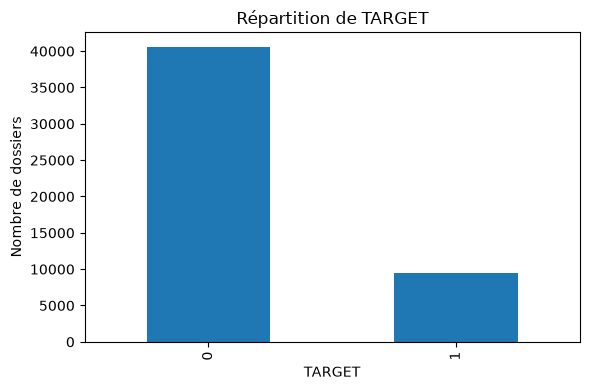

In [18]:
if "TARGET" in df.columns:
    target_counts = df["TARGET"].value_counts(dropna=False).sort_index()
    target_pct = df["TARGET"].value_counts(normalize=True, dropna=False).sort_index() * 100
    target_report = pd.DataFrame({"effectif": target_counts, "pourcentage": target_pct.round(2)})
    display(target_report)

    ax = df["TARGET"].value_counts(dropna=False).sort_index().plot(
        kind="bar", figsize=(6, 4), title="Répartition de TARGET"
    )
    ax.set_xlabel("TARGET")
    ax.set_ylabel("Nombre de dossiers")
    plt.tight_layout()
    plt.show()
else:
    print("TARGET absent de la table principale. Identifiez la table qui contient la cible.")


## 7. Statistiques descriptives des variables numériques

In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T if numeric_cols else "Aucune variable numérique détectée.")

if numeric_cols:
    display(df[numeric_cols].skew(numeric_only=True).rename("skewness").to_frame())


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,"50,000.000","124,999.500","14,433.901","100,000.000","112,499.750","124,999.500","137,499.250","149,999.000"
AMOUNT_REQUESTED_MAD,"50,000.000","120,082.600","201,631.531","5,000.000","23,140.000","41,574.000","94,581.250","1,800,000.000"
CREDIT_TERM_MONTHS,"50,000.000",76.859,90.810,6.000,24.000,48.000,60.000,360.000
INTEREST_RATE_ANNUAL_PCT,"50,000.000",8.531,2.389,3.500,6.880,8.510,10.130,17.790
ESTIMATED_MONTHLY_INSTALLMENT_MAD,"50,000.000","2,158.480","2,163.477",22.450,754.890,"1,472.430","2,815.760","26,525.240"
CREDIT_TO_ANNUAL_INCOME,"50,000.000",1.644,39.007,0.163,0.321,0.448,0.966,"5,000.000"
PAYMENT_TO_INCOME_RATIO,"50,000.000",0.423,0.217,0.046,0.258,0.384,0.550,1.991
DEBT_TO_INCOME_RATIO,"50,000.000",1.740,39.006,0.169,0.414,0.554,1.061,"5,000.000"
TARGET,"50,000.000",0.189,0.391,0.000,0.000,0.000,0.000,1.000


,skewness
SK_ID_CURR,0.000
AMOUNT_REQUESTED_MAD,3.242
CREDIT_TERM_MONTHS,1.963
INTEREST_RATE_ANNUAL_PCT,0.122
ESTIMATED_MONTHLY_INSTALLMENT_MAD,2.631
CREDIT_TO_ANNUAL_INCOME,126.372
PAYMENT_TO_INCOME_RATIO,0.945
DEBT_TO_INCOME_RATIO,126.372
TARGET,1.591


## 8. Distributions des variables numériques

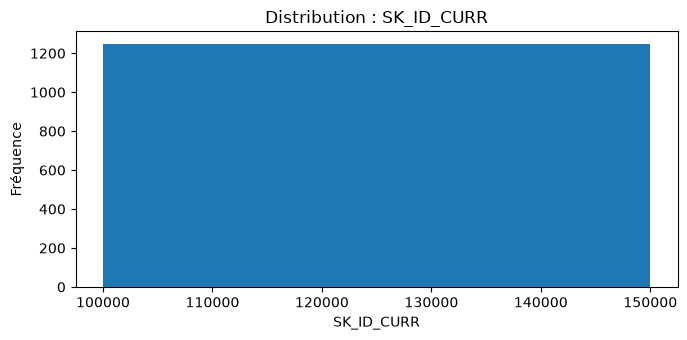

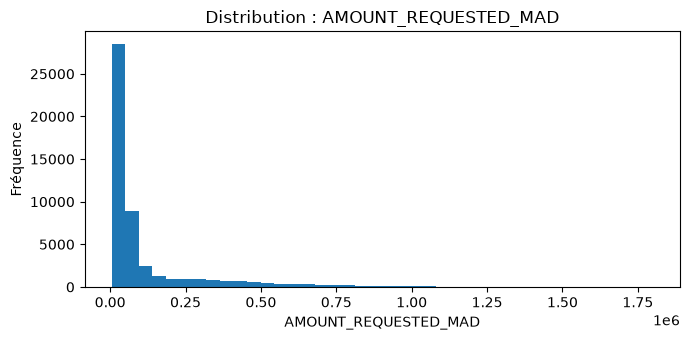

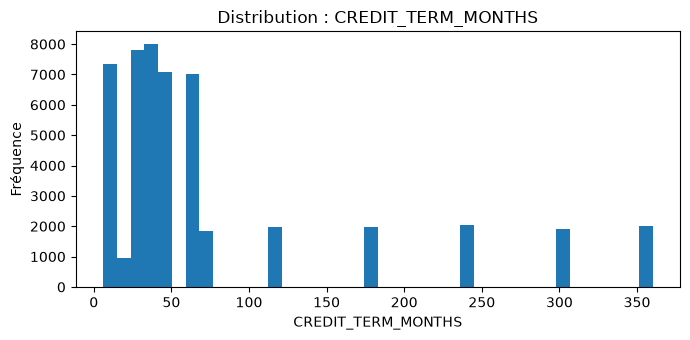

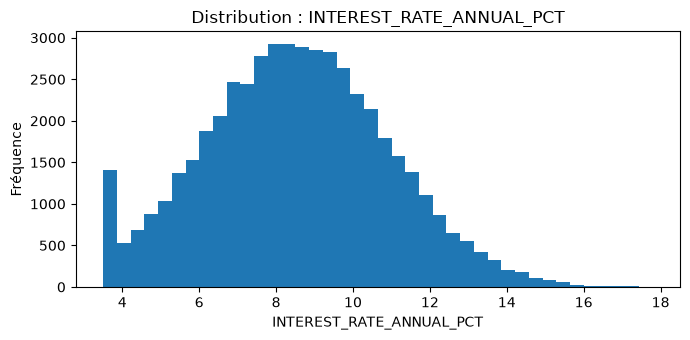

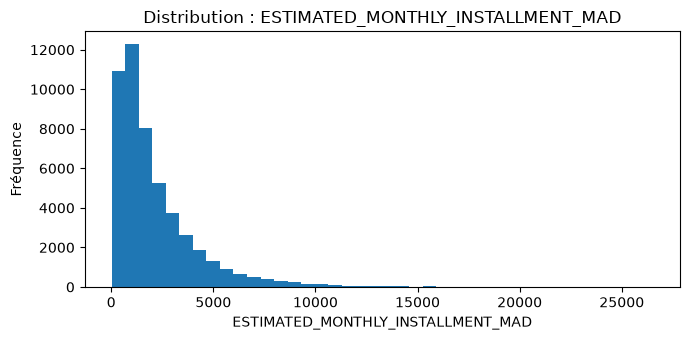

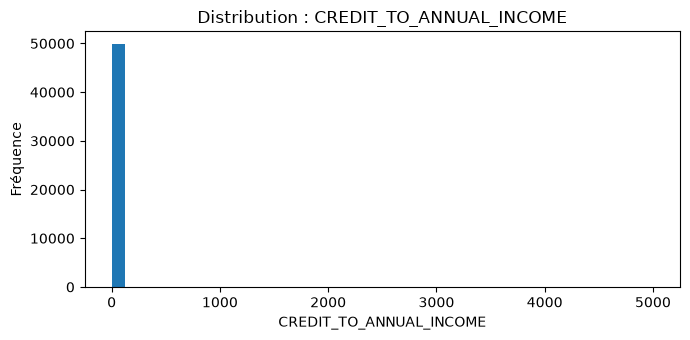

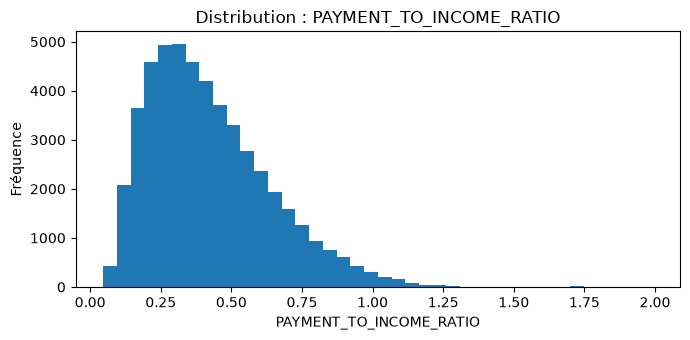

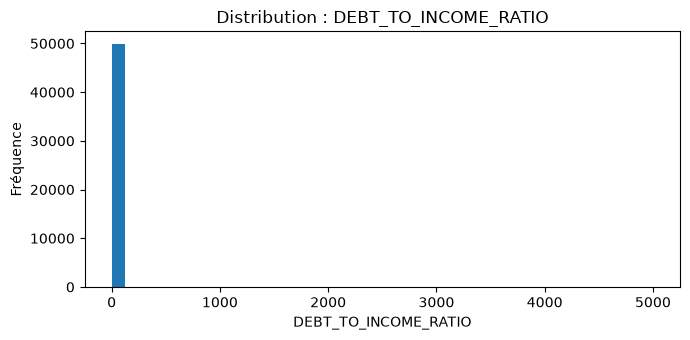

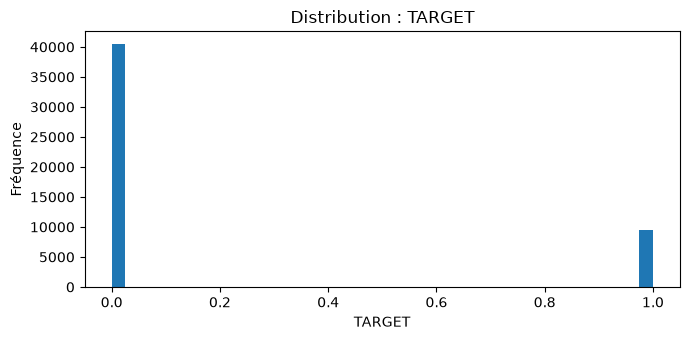

In [20]:
# Limiter le nombre de graphiques pour garder le notebook lisible.
plot_cols = numeric_cols[:12]
for col in plot_cols:
    series = df[col].replace([np.inf, -np.inf], np.nan).dropna()
    if series.empty:
        continue
    plt.figure(figsize=(7, 3.5))
    plt.hist(series, bins=40)
    plt.title(f"Distribution : {col}")
    plt.xlabel(col)
    plt.ylabel("Fréquence")
    plt.tight_layout()
    plt.show()


## 9. Analyse des valeurs aberrantes (IQR)
Cette étape signale les valeurs extrêmes ; elle ne les supprime pas automatiquement. Une valeur extrême peut être financièrement plausible.

In [21]:
outlier_rows = []
for col in numeric_cols:
    s = df[col].dropna()
    if s.nunique() < 5:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({
        "variable": col, "borne_basse_IQR": lower,
        "borne_haute_IQR": upper, "nb_valeurs_extremes": count,
        "taux_%": round(count / len(s) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values("taux_%", ascending=False)
display(outlier_report)
outlier_report.to_csv(REPORT_DIR / "analyse_outliers_iqr.csv", index=False)


,variable,borne_basse_IQR,borne_haute_IQR,nb_valeurs_extremes,taux_%
7,DEBT_TO_INCOME_RATIO,-0.556,2.032,10210,20.420
5,CREDIT_TO_ANNUAL_INCOME,-0.646,1.933,10211,20.420
2,CREDIT_TERM_MONTHS,-30.000,114.000,9885,19.770
1,AMOUNT_REQUESTED_MAD,"-84,021.875","201,743.125",8371,16.740
4,ESTIMATED_MONTHLY_INSTALLMENT_MAD,"-2,336.415","5,907.065",2990,5.980
6,PAYMENT_TO_INCOME_RATIO,-0.179,0.987,793,1.590
3,INTEREST_RATE_ANNUAL_PCT,2.005,15.005,214,0.430
0,SK_ID_CURR,"75,000.500","174,998.500",0,0.000


## 10. Corrélations numériques

,SK_ID_CURR,AMOUNT_REQUESTED_MAD,CREDIT_TERM_MONTHS,INTEREST_RATE_ANNUAL_PCT,ESTIMATED_MONTHLY_INSTALLMENT_MAD,CREDIT_TO_ANNUAL_INCOME,PAYMENT_TO_INCOME_RATIO,DEBT_TO_INCOME_RATIO,TARGET
SK_ID_CURR,1.000,0.000,-0.000,0.000,0.010,-0.000,0.000,-0.000,0.010
AMOUNT_REQUESTED_MAD,0.000,1.000,0.680,-0.130,0.700,0.030,0.420,0.030,0.240
CREDIT_TERM_MONTHS,-0.000,0.680,1.000,-0.150,0.230,0.030,0.260,0.030,0.230
INTEREST_RATE_ANNUAL_PCT,0.000,-0.130,-0.150,1.000,0.000,-0.010,0.010,-0.010,-0.040
ESTIMATED_MONTHLY_INSTALLMENT_MAD,0.010,0.700,0.230,0.000,1.000,0.010,0.540,0.010,0.160
CREDIT_TO_ANNUAL_INCOME,-0.000,0.030,0.030,-0.010,0.010,1.000,0.030,1.000,0.030
PAYMENT_TO_INCOME_RATIO,0.000,0.420,0.260,0.010,0.540,0.030,1.000,0.030,0.230
DEBT_TO_INCOME_RATIO,-0.000,0.030,0.030,-0.010,0.010,1.000,0.030,1.000,0.030
TARGET,0.010,0.240,0.230,-0.040,0.160,0.030,0.230,0.030,1.000


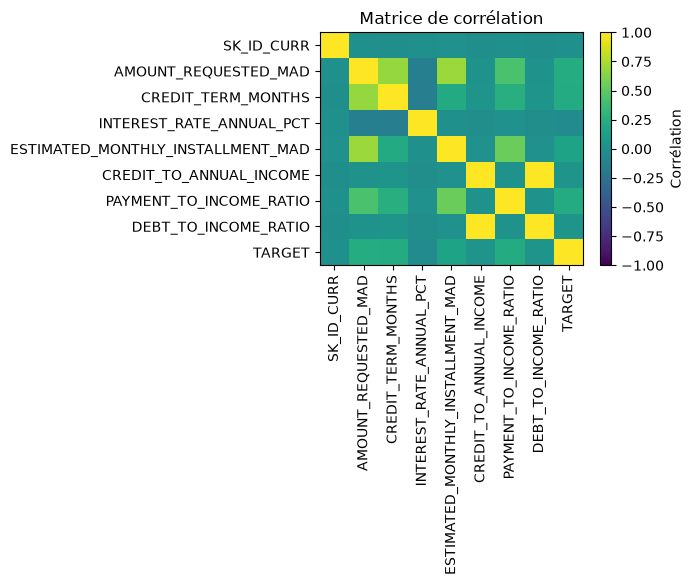

In [22]:
if len(numeric_cols) >= 2:
    corr = df[numeric_cols].corr(numeric_only=True)
    display(corr.round(2))
    plt.figure(figsize=(min(14, 1 + len(numeric_cols)*0.65), min(11, 1 + len(numeric_cols)*0.55)))
    plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    plt.colorbar(label="Corrélation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.index)), corr.index)
    plt.title("Matrice de corrélation")
    plt.tight_layout()
    plt.show()


## 11. Analyse des variables financières par TARGET

In [23]:
if "TARGET" in df.columns:
    # Afficher les médianes par classe pour les variables numériques.
    selected = [c for c in numeric_cols if c != "TARGET"][:15]
    if selected:
        display(df.groupby("TARGET")[selected].median().T)

    # Taux de défaut par modalité pour quelques variables catégorielles.
    categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    for col in categorical_cols[:6]:
        rates = df.groupby(col, dropna=False)["TARGET"].mean().sort_values(ascending=False)
        if len(rates) <= 20:
            display(rates.rename("taux_defaut").to_frame())


TARGET,0,1
SK_ID_CURR,"124,957.500","125,165.500"
AMOUNT_REQUESTED_MAD,"38,634.000","75,807.000"
CREDIT_TERM_MONTHS,36.000,60.000
INTEREST_RATE_ANNUAL_PCT,8.550,8.340
ESTIMATED_MONTHLY_INSTALLMENT_MAD,"1,375.385","2,098.165"
CREDIT_TO_ANNUAL_INCOME,0.423,0.963
PAYMENT_TO_INCOME_RATIO,0.362,0.500
DEBT_TO_INCOME_RATIO,0.524,1.061


,taux_defaut
CREDIT_TYPE,
Immobilier,0.408
Automobile,0.165
Équipement,0.138
Trésorerie,0.137
Personnel,0.120


,taux_defaut
TARGET_LABEL,
Défaut observé,1.000
Remboursement sans défaut observé,0.000


## 12. Contrôles anti-fuite de données (data leakage)
Vérifiez que les variables explicatives sont connues à la date où la prédiction est censée être faite. Les retards de paiement, remboursements et statuts observés après cette date ne doivent pas entrer dans les features.

In [24]:
# Liste indicative à examiner manuellement : adapter aux colonnes réellement présentes.
leakage_keywords = [
    "future", "after", "post", "repayment", "payment_date",
    "days_late", "delay", "default_date", "recovery", "paid_amount"
]
possible_leakage = [
    c for c in df.columns
    if any(k in c.lower() for k in leakage_keywords)
]
print("Colonnes à examiner pour un risque de fuite :", possible_leakage)
print("Ne supprimez pas automatiquement ces colonnes : vérifiez leur temporalité et leur sens métier.")


Colonnes à examiner pour un risque de fuite : []
Ne supprimez pas automatiquement ces colonnes : vérifiez leur temporalité et leur sens métier.


## 13. Synthèse automatique des contrôles

In [25]:
summary = {
    "table_principale": MAIN_TABLE,
    "nombre_lignes": int(df.shape[0]),
    "nombre_colonnes": int(df.shape[1]),
    "doublons_lignes": duplicate_rows,
    "cellules_manquantes": int(df.isna().sum().sum()),
    "colonnes_constantes": [c for c in df.columns if df[c].nunique(dropna=False) <= 1],
    "colonnes_a_examiner_leakage": possible_leakage
}
if "TARGET" in df.columns:
    summary["distribution_TARGET"] = {
        str(k): int(v) for k, v in df["TARGET"].value_counts(dropna=False).items()
    }

summary


{'table_principale': 'credit_applications',
 'nombre_lignes': 50000,
 'nombre_colonnes': 12,
 'doublons_lignes': 0,
 'cellules_manquantes': 0,
 'colonnes_constantes': [],
 'colonnes_a_examiner_leakage': [],
 'distribution_TARGET': {'0': 40562, '1': 9438}}

In [26]:
import json
with open(REPORT_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)

print("Fichiers de synthèse exportés dans :", REPORT_DIR.resolve())


Fichiers de synthèse exportés dans : C:\Users\manal\OneDrive\Desktop\Smart-Banking-Analytics\reports
